# NYC 311 · Hurricane Ida — Neo4j graph to *explain* the Qdrant results

**Part 2 of the City Brain citizen-calls pipeline.**

* **Part 1** (`nyc311_ida_preprocessing.ipynb`) cleaned the data and put one generic vector per call in **Qdrant**: *"incident type + severity"*. Qdrant answers **"which past calls look like this one?"**
* **This notebook** puts the same calls in **Neo4j** as a graph. The graph holds what the vectors deliberately leave out: **where, when, which wave of the storm, what else surged at the same time**. Neo4j answers **"why does it look like this, and what was going on around it?"**
* **Section 7 combines both**: take a new situation, find similar past calls in Qdrant, then explain each one with the graph.

```
 new situation ──embed──►  Qdrant  ──►  most similar past calls  (point ids + scores)
                                                │  same ids
                                                ▼
                                             Neo4j  ──►  why: type, surge wave, borough, zone,
                                                          what else was surging in that hour
```

The two stores are joined by one key: **`point_id`** (Qdrant point id = `Call.id` in Neo4j). That is why Qdrant can stay small and generic while the context lives in the graph.

### Graph model

| Node | Meaning | Key properties |
|---|---|---|
| `Call` | one 311 call | `id`, `call_type`, `surge_level`, `city_recent_60m`, `ts`, `phase`, `lat`, `lon`, `text` |
| `CallType` | e.g. *Sewer backup* | `name`, `label`, `call_group` |
| `IncidentType` | `flood`, `traffic_signal_failure` | `name` |
| `Window` | one hour of the timeline | `id`, `n_flood`, `n_signal`, `n_total`, `phase` |
| `Episode` | a **surge wave**: consecutive busy hours | `id`, `start`, `end`, `peak_calls`, `total_calls`, `top_borough` |
| `Zone` | ~1 km grid cell | `id`, `lat`, `lon` |
| `Borough` | | `name` |

| Relationship | |
|---|---|
| `(Call)-[:OF_TYPE]->(CallType)-[:INSTANCE_OF]->(IncidentType)` | what kind of call |
| `(Call)-[:IN_WINDOW]->(Window)-[:NEXT]->(Window)` | when (a chain of hours) |
| `(Window)-[:PART_OF]->(Episode)` | which surge wave |
| `(Call)-[:IN_ZONE]->(Zone)-[:IN_BOROUGH]->(Borough)`, `(Call)-[:IN_BOROUGH]->(Borough)` | where |
| `(IncidentType)-[:CO_SURGES_WITH {ratio}]->(IncidentType)` | measured from the data: how much more of B happens while A is in a surge wave |

> Place and time live **only in the graph**, so the vectors in Qdrant stay general and reusable for other cities and events. `CO_SURGES_WITH` is a *co-occurrence measured in this dataset*, not a proof of cause.

## 0 · Setup

In [ ]:
import os, json, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import networkx as nx
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running in Colab:", IN_COLAB)

Running in Colab: True


In [ ]:
# ---- switches ---------------------------------------------------------------
RUN_NEO4J    = True      # sections 3-6: load the graph into Neo4j and query it
RUN_COMBINE  = True      # section 7: Qdrant similarity + Neo4j explanation (needs both clouds)
CLEAR_GRAPH  = True      # True = first delete the nodes THIS notebook created earlier (tagged ds = DS)

# ---- constants --------------------------------------------------------------
TZ           = "America/New_York"
STORM_START  = pd.Timestamp("2021-09-01 18:00", tz=TZ)
STORM_END    = pd.Timestamp("2021-09-02 06:00", tz=TZ)
EPISODE_MIN  = 50         # >= this many flood calls in an hour = "busy hour"
MERGE_GAP_H  = 2          # busy hours at most this far apart belong to the same wave
DS           = "nyc311-ida"                 # tag on every node we create
QDRANT_COLLECTION = "nyc311_calls"          # same collection as part 1

# ---- chart style (same as part 1) ---------------------------------------------
INK, INK2, SURF, GRIDC = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
BLUE = "#2a78d6"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRIDC, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRIDC, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "font.size": 10,
})

## 1 · Load the clean export from part 1

Part 1 wrote `output/nyc311_ida_clean.csv`. Upload that file here (or put it next to the notebook).
It already contains `point_id`, the same id Qdrant uses.

In [ ]:
CLEAN_PATH = "nyc311_ida_clean.csv"

if not os.path.exists(CLEAN_PATH):
    if IN_COLAB:
        from google.colab import files
        print("Select nyc311_ida_clean.csv (output of part 1) ...")
        up = files.upload()
        CLEAN_PATH = next(iter(up))
    else:
        raise FileNotFoundError(f"{CLEAN_PATH} not found - set CLEAN_PATH.")

df = pd.read_csv(CLEAN_PATH)
df["created_at"] = pd.to_datetime(df.created_at, utc=True).dt.tz_convert(TZ)
df["has_geo"]    = df.has_geo.astype(bool)
df = df.sort_values("created_at", kind="stable").reset_index(drop=True)
assert df.point_id.is_unique, "point_id must be unique"
print(f"{len(df):,} calls  |  {df.created_at.min():%d %b %H:%M} -> {df.created_at.max():%d %b %H:%M}")
df[["point_id", "created_at", "call_label", "incident_type", "borough", "zone_id", "surge_level", "city_recent_60m"]].head()

6,273 calls  |  31 Aug 00:19 -> 03 Sep 23:55


,point_id,created_at,call_label,incident_type,borough,zone_id,surge_level,city_recent_60m
0,0bee7598-5159-530d-a0f6-8bb96f8e4406,2021-08-31 00:19:00-04:00,Traffic signal failure,traffic_signal_failure,Manhattan,unknown,isolated report,0
1,76684da9-986c-5562-9f1f-752b1aa0d126,2021-08-31 01:37:00-04:00,Traffic signal failure,traffic_signal_failure,Brooklyn,unknown,isolated report,0
2,f3728779-7528-5eae-83c6-9d114c48a4be,2021-08-31 01:44:00-04:00,Traffic signal failure,traffic_signal_failure,Brooklyn,unknown,isolated report,1
3,074371aa-02e9-53e4-92ae-473cb562e1f7,2021-08-31 02:24:00-04:00,Traffic signal failure,traffic_signal_failure,Manhattan,unknown,isolated report,2
4,3d547164-79de-5465-937c-99d57f10ca22,2021-08-31 04:35:00-04:00,Traffic signal failure,traffic_signal_failure,Bronx,unknown,isolated report,0


## 2 · Build the graph tables in pandas

We prepare every node and relationship as a table first, so we can look at them before sending anything to Neo4j.

### 2.1 Hourly windows and surge waves (`Episode`)

A **busy hour** = at least `EPISODE_MIN` flood calls. Busy hours at most `MERGE_GAP_H` hours apart are merged into one **wave**.
This is what lets the graph say *"this call belongs to the first wave of the storm"* instead of just giving a timestamp.

In [ ]:
hours = pd.date_range(df.created_at.min().floor("h"), df.created_at.max().floor("h"), freq="h")
by_h  = df.assign(h=df.created_at.dt.floor("h"))

def hourly(mask=None):
    sub = by_h if mask is None else by_h[mask]
    return sub.groupby("h").size().reindex(hours, fill_value=0)

win = pd.DataFrame({
    "n_flood":  hourly(by_h.incident_type.eq("flood")),
    "n_signal": hourly(by_h.incident_type.eq("traffic_signal_failure")),
    "n_total":  hourly(),
}, index=hours)
win["id"]       = hours.strftime("%Y-%m-%dT%H")
win["start_ts"] = (hours - pd.Timestamp("1970-01-01", tz="UTC")).total_seconds().astype("int64")
win["phase"]    = np.select([hours < STORM_START, hours < STORM_END], ["pre_storm", "storm_night"], default="aftermath")

# ---- waves: busy hours merged when close together ----
busy = np.flatnonzero((win.n_flood >= EPISODE_MIN).to_numpy())
spans = []
for i in busy:
    if spans and i - spans[-1][1] - 1 <= MERGE_GAP_H:
        spans[-1][1] = i
    else:
        spans.append([i, i])

win["episode_id"] = pd.Series([None] * len(win), index=hours, dtype=object)
episodes = []
for k, (a, b) in enumerate(spans, 1):
    span = win.iloc[a:b + 1]
    win.iloc[a:b + 1, win.columns.get_loc("episode_id")] = f"E{k}"
    fl = by_h[by_h.h.between(span.index[0], span.index[-1]) & by_h.incident_type.eq("flood")]
    peak_h = span.n_flood.idxmax()
    episodes.append({
        "id": f"E{k}", "start": f"{span.index[0]:%d %b %H:%M}", "end": f"{span.index[-1] + pd.Timedelta(hours=1):%d %b %H:%M}",
        "hours": int(b - a + 1), "peak_calls": int(span.n_flood.max()), "peak_window": f"{peak_h:%d %b %H:00}",
        "total_calls": int(len(fl)), "top_borough": fl.borough.mode().iat[0] if fl.borough.notna().any() else None,
        "start_ts": int(span.start_ts.iloc[0]), "end_ts": int(span.start_ts.iloc[-1] + 3600),
    })
ep = pd.DataFrame(episodes)
print(f"{len(win)} hourly windows, {len(ep)} surge waves (>= {EPISODE_MIN} flood calls/hour, gaps <= {MERGE_GAP_H} h merged)")
ep.drop(columns=["start_ts", "end_ts"])

96 hourly windows, 3 surge waves (>= 50 flood calls/hour, gaps <= 2 h merged)


,id,start,end,hours,peak_calls,peak_window,total_calls,top_borough
0,E1,01 Sep 20:00,02 Sep 03:00,7,659,01 Sep 22:00,2121,Queens
1,E2,02 Sep 06:00,02 Sep 21:00,15,311,02 Sep 09:00,2284,Queens
2,E3,03 Sep 09:00,03 Sep 16:00,7,101,03 Sep 11:00,530,Queens


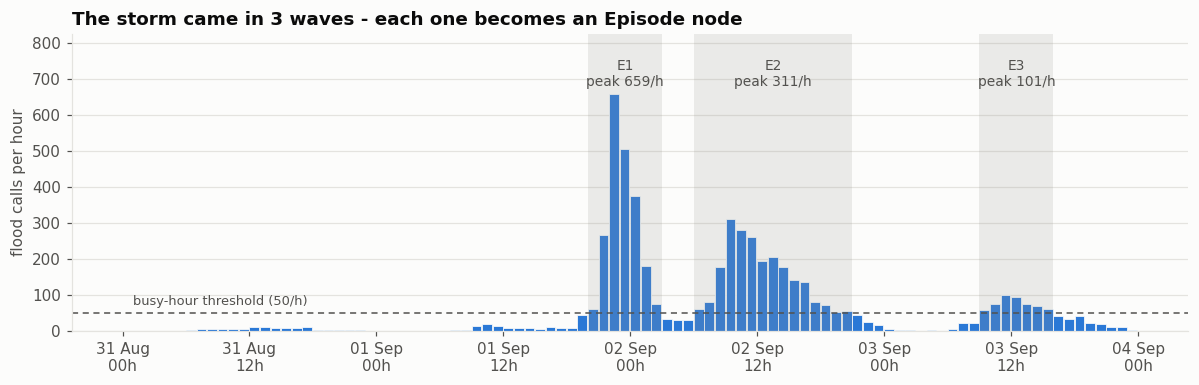

In [ ]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(win.index, win.n_flood, width=1 / 24 * 0.92, align="edge", color=BLUE, edgecolor=SURF, linewidth=0.5)
for r in ep.itertuples():
    t0 = pd.Timestamp(r.start_ts, unit="s", tz="UTC").tz_convert(TZ); t1 = pd.Timestamp(r.end_ts, unit="s", tz="UTC").tz_convert(TZ)
    ax.axvspan(t0, t1, color="#9a9992", alpha=0.18, lw=0)
    ax.text(t0 + (t1 - t0) / 2, win.n_flood.max() * 1.02, f"{r.id}\npeak {r.peak_calls}/h", ha="center", va="bottom", fontsize=9, color=INK2)
ax.axhline(EPISODE_MIN, color=INK2, lw=1, ls=(0, (4, 3)))
ax.text(win.index[0] + pd.Timedelta(hours=1), EPISODE_MIN + 14, f"busy-hour threshold ({EPISODE_MIN}/h)", fontsize=8.5, color=INK2, ha="left", va="bottom")
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12], tz=win.index.tz))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%Hh", tz=win.index.tz))
ax.set_ylim(0, win.n_flood.max() * 1.25); ax.set_ylabel("flood calls per hour")
ax.set_title(f"The storm came in {len(ep)} waves - each one becomes an Episode node")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

### 2.2 How much more happens during a wave? (`CO_SURGES_WITH`)

Average traffic-signal failures per hour **inside** waves vs **outside**. This becomes a property on the edge `flood → traffic_signal_failure`.

In [ ]:
in_wave = win.episode_id.notna()
rate_in, rate_out = win.loc[in_wave, "n_signal"].mean(), win.loc[~in_wave, "n_signal"].mean()
cosurge = {"a": "flood", "b": "traffic_signal_failure",
           "per_hour_in_waves": round(float(rate_in), 2), "per_hour_outside": round(float(rate_out), 2),
           "ratio": round(float(rate_in / rate_out), 1) if rate_out > 0 else None}
print(f"traffic signal failures per hour: {cosurge['per_hour_in_waves']} inside waves vs {cosurge['per_hour_outside']} outside  ->  x{cosurge['ratio']}")

traffic signal failures per hour: 15.93 inside waves vs 2.96 outside  ->  x5.4


### 2.3 Node and relationship tables

In [ ]:
def rows(frame):
    """DataFrame -> list of plain dicts (NaN -> None, numpy -> python), safe to send to Neo4j."""
    return json.loads(frame.to_json(orient="records"))

# ---- nodes ----
n_incident = rows(pd.DataFrame({"name": sorted(df.incident_type.unique())}))
n_calltype = rows(df[["call_type", "call_label", "call_group", "incident_type"]].drop_duplicates()
                    .rename(columns={"call_type": "name", "call_label": "label", "call_group": "call_group"}))
n_borough  = rows(pd.DataFrame({"name": sorted(df.borough.dropna().unique())}))
zones = (df[df.has_geo].groupby("zone_id")
           .agg(lat=("latitude", "mean"), lon=("longitude", "mean"),
                borough=("borough", lambda s: s.mode().iat[0] if s.notna().any() else None)).reset_index()
           .rename(columns={"zone_id": "id"}))
n_zone     = rows(zones)
n_window   = rows(win[["id", "n_flood", "n_signal", "n_total", "phase", "start_ts"]])
n_episode  = rows(ep)
n_call     = rows(df.rename(columns={"point_id": "id", "latitude": "lat", "longitude": "lon"})
                    [["id", "call_type", "surge_level", "city_recent_60m", "ts", "phase", "has_geo", "lat", "lon", "text"]])

# ---- relationships ----
r_instance = [{"a": r["name"], "b": r["incident_type"]} for r in n_calltype]
r_oftype   = rows(df[["point_id", "call_type"]].rename(columns={"point_id": "a", "call_type": "b"}))
r_inwindow = rows(pd.DataFrame({"a": df.point_id, "b": df.created_at.dt.floor("h").dt.strftime("%Y-%m-%dT%H")}))
r_inzone   = rows(df.loc[df.has_geo, ["point_id", "zone_id"]].rename(columns={"point_id": "a", "zone_id": "b"}))
r_inborough= rows(df.loc[df.borough.notna(), ["point_id", "borough"]].rename(columns={"point_id": "a", "borough": "b"}))
r_zone_b   = rows(zones.dropna(subset=["borough"])[["id", "borough"]].rename(columns={"id": "a", "borough": "b"}))
r_next     = [{"a": win.id.iloc[i], "b": win.id.iloc[i + 1]} for i in range(len(win) - 1)]
r_partof   = rows(win.loc[win.episode_id.notna(), ["id", "episode_id"]].rename(columns={"id": "a", "episode_id": "b"}))

plan = pd.DataFrame([
    ("nodes", "Call", len(n_call)), ("nodes", "CallType", len(n_calltype)), ("nodes", "IncidentType", len(n_incident)),
    ("nodes", "Window", len(n_window)), ("nodes", "Episode", len(n_episode)), ("nodes", "Zone", len(n_zone)), ("nodes", "Borough", len(n_borough)),
    ("rels", "OF_TYPE", len(r_oftype)), ("rels", "INSTANCE_OF", len(r_instance)), ("rels", "IN_WINDOW", len(r_inwindow)),
    ("rels", "NEXT", len(r_next)), ("rels", "PART_OF", len(r_partof)), ("rels", "IN_ZONE", len(r_inzone)),
    ("rels", "IN_BOROUGH", len(r_inborough) + len(r_zone_b)), ("rels", "CO_SURGES_WITH", 1),
], columns=["kind", "name", "to_load"])
print(f"{plan[plan.kind == 'nodes'].to_load.sum():,} nodes and {plan[plan.kind == 'rels'].to_load.sum():,} relationships will be created")
plan

7,075 nodes and 25,661 relationships will be created


,kind,name,to_load
0,nodes,Call,6273
1,nodes,CallType,5
2,nodes,IncidentType,2
3,nodes,Window,96
4,nodes,Episode,3
5,nodes,Zone,691
6,nodes,Borough,5
7,rels,OF_TYPE,6273
8,rels,INSTANCE_OF,5
9,rels,IN_WINDOW,6273


## 3 · Connect to Neo4j (Aura / your cloud instance)

Add these in Colab **Secrets** (left sidebar, key icon) and switch on *Notebook access*:

| Secret | Example |
|---|---|
| `NEO4J_URI` | `neo4j+s://xxxxxxxx.databases.neo4j.io` |
| `NEO4J_USERNAME` | `neo4j` |
| `NEO4J_PASSWORD` | the password from the Aura credentials file |
| `NEO4J_DATABASE` | *(optional)* default `neo4j` |

If a secret is missing, the cell asks for it (the password is typed hidden). Nothing is stored in the notebook.
An Aura Free instance that was idle may be **paused** - resume it in the Aura console first.

In [ ]:
import subprocess, sys

def secret(name, prompt, hidden=False, default=None):
    """Colab Secrets -> environment variable -> prompt."""
    import getpass
    val = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            val = userdata.get(name)
        except Exception:
            val = None
    val = val or os.environ.get(name)
    if not val and default is None:
        val = (getpass.getpass if hidden else input)(prompt + ": ")
    return (val or default).strip()

_driver, NEO4J_DB = None, "neo4j"

def get_driver():
    """Create the Neo4j driver once and reuse it."""
    global _driver, NEO4J_DB
    if _driver is None:
        try:
            import neo4j  # noqa: F401
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "neo4j"], check=True)
        from neo4j import GraphDatabase
        uri  = secret("NEO4J_URI", "Neo4j URI (neo4j+s://...)")
        user = secret("NEO4J_USERNAME", "Neo4j username", default="neo4j")
        pwd  = secret("NEO4J_PASSWORD", "Neo4j password", hidden=True)
        NEO4J_DB = secret("NEO4J_DATABASE", "", default="neo4j")
        drv = GraphDatabase.driver(uri, auth=(user, pwd))
        try:
            drv.verify_connectivity()
        except Exception as e:
            raise RuntimeError(f"Could not connect to Neo4j at {uri}. Is the Aura instance running (not paused)? "
                               f"Check URI / user / password. Original error: {e}")
        _driver = drv
    return _driver

def q(query, **params):
    """Run a read query, return a list of plain dicts."""
    with get_driver().session(database=NEO4J_DB) as s:
        return [r.data() for r in s.run(query, **params)]

def q_raw(query, **params):
    """Run a query and keep the driver objects (nodes / paths) - used for drawing."""
    with get_driver().session(database=NEO4J_DB) as s:
        return list(s.run(query, **params))

if RUN_NEO4J:
    get_driver()
    print("Connected to Neo4j. Database:", NEO4J_DB)
    print("Nodes already in it:", q("MATCH (n) RETURN count(n) AS n")[0]["n"])
else:
    print("RUN_NEO4J is False - skipping the connection.")

Connected to Neo4j. Database: f354174c
Nodes already in it: 0


## 4 · Load the graph

* Every node gets a **uniqueness constraint** on its key (this also creates the index that makes the loads fast).
* Everything uses `MERGE`, so **running it twice does not duplicate anything**.
* Every node created here is tagged `ds = "nyc311-ida"`. `CLEAR_GRAPH = True` deletes **only** nodes with that tag, never the rest of your database.

In [ ]:
CONSTRAINTS = [
    ("Call", "id"), ("CallType", "name"), ("IncidentType", "name"), ("Window", "id"),
    ("Episode", "id"), ("Zone", "id"), ("Borough", "name"),
]

def clear_graph():
    total = 0
    with get_driver().session(database=NEO4J_DB) as s:
        while True:
            n = s.run("MATCH (n {ds: $ds}) WITH n LIMIT 5000 DETACH DELETE n RETURN count(*) AS n", ds=DS).single()["n"]
            total += n
            if n == 0:
                break
    print(f"deleted {total:,} nodes tagged ds = '{DS}'")

def load(query, data, size=1000, **extra):
    """Send `data` to Neo4j in batches; `query` must start with UNWIND $rows AS r."""
    with get_driver().session(database=NEO4J_DB) as s:
        for i in range(0, len(data), size):
            s.run(query, rows=data[i:i + size], ds=DS, **extra).consume()

def load_rel(rel, a_label, a_key, b_label, b_key, data, size=2000):
    load(f"UNWIND $rows AS r MATCH (a:{a_label} {{{a_key}: r.a}}), (b:{b_label} {{{b_key}: r.b}}) MERGE (a)-[:{rel}]->(b)", data, size)

Q_INCIDENT = "UNWIND $rows AS r MERGE (i:IncidentType {name: r.name}) SET i.ds = $ds"
Q_CALLTYPE = "UNWIND $rows AS r MERGE (t:CallType {name: r.name}) SET t.label = r.label, t.call_group = r.call_group, t.ds = $ds"
Q_BOROUGH  = "UNWIND $rows AS r MERGE (b:Borough {name: r.name}) SET b.ds = $ds"
Q_ZONE     = "UNWIND $rows AS r MERGE (z:Zone {id: r.id}) SET z.lat = r.lat, z.lon = r.lon, z.ds = $ds"
Q_WINDOW   = ("UNWIND $rows AS r MERGE (w:Window {id: r.id}) "
              "SET w.n_flood = r.n_flood, w.n_signal = r.n_signal, w.n_total = r.n_total, w.phase = r.phase, w.start_ts = r.start_ts, w.ds = $ds")
Q_EPISODE  = ("UNWIND $rows AS r MERGE (e:Episode {id: r.id}) "
              "SET e.start = r.start, e.end = r.end, e.hours = r.hours, e.peak_calls = r.peak_calls, e.peak_window = r.peak_window, "
              "e.total_calls = r.total_calls, e.top_borough = r.top_borough, e.start_ts = r.start_ts, e.end_ts = r.end_ts, e.ds = $ds")
Q_CALL     = ("UNWIND $rows AS r MERGE (c:Call {id: r.id}) "
              "SET c.call_type = r.call_type, c.surge_level = r.surge_level, c.city_recent_60m = r.city_recent_60m, c.ts = r.ts, "
              "c.phase = r.phase, c.has_geo = r.has_geo, c.lat = r.lat, c.lon = r.lon, c.text = r.text, c.ds = $ds")
Q_COSURGE  = ("MATCH (a:IncidentType {name: $a}), (b:IncidentType {name: $b}) MERGE (a)-[r:CO_SURGES_WITH]->(b) "
              "SET r.per_hour_in_waves = $pin, r.per_hour_outside = $pout, r.ratio = $ratio")

def load_graph():
    with get_driver().session(database=NEO4J_DB) as s:
        for label, key in CONSTRAINTS:
            s.run(f"CREATE CONSTRAINT {label.lower()}_{key} IF NOT EXISTS FOR (n:{label}) REQUIRE n.{key} IS UNIQUE").consume()
    if CLEAR_GRAPH:
        clear_graph()
    # nodes
    load(Q_INCIDENT, n_incident); load(Q_CALLTYPE, n_calltype); load(Q_BOROUGH, n_borough)
    load(Q_ZONE, n_zone); load(Q_WINDOW, n_window); load(Q_EPISODE, n_episode); load(Q_CALL, n_call)
    # relationships
    load_rel("INSTANCE_OF", "CallType", "name", "IncidentType", "name", r_instance)
    load_rel("IN_BOROUGH", "Zone", "id", "Borough", "name", r_zone_b)
    load_rel("NEXT", "Window", "id", "Window", "id", r_next)
    load_rel("PART_OF", "Window", "id", "Episode", "id", r_partof)
    load_rel("OF_TYPE", "Call", "id", "CallType", "name", r_oftype)
    load_rel("IN_WINDOW", "Call", "id", "Window", "id", r_inwindow)
    load_rel("IN_ZONE", "Call", "id", "Zone", "id", r_inzone)
    load_rel("IN_BOROUGH", "Call", "id", "Borough", "name", r_inborough)
    with get_driver().session(database=NEO4J_DB) as s:
        s.run(Q_COSURGE, a=cosurge["a"], b=cosurge["b"], pin=cosurge["per_hour_in_waves"],
              pout=cosurge["per_hour_outside"], ratio=cosurge["ratio"]).consume()

if RUN_NEO4J:
    load_graph()
    got_nodes = {r["label"]: r["n"] for r in q("MATCH (n {ds: $ds}) RETURN labels(n)[0] AS label, count(*) AS n ORDER BY n DESC", ds=DS)}
    got_rels  = {r["rel"]: r["n"] for r in q("MATCH ({ds: $ds})-[r]->() RETURN type(r) AS rel, count(*) AS n ORDER BY n DESC", ds=DS)}
    check = plan.copy()
    check["in_neo4j"] = [got_nodes.get(n, 0) if k == "nodes" else got_rels.get(n, 0) for k, n in zip(check.kind, check.name)]
    check["ok"] = check.in_neo4j >= check.to_load
    display(check)
    assert check.ok.all(), "Some counts are lower than expected - see the table above"
    print("Graph loaded and verified.")
else:
    print("RUN_NEO4J is False - skipping the load.")

deleted 0 nodes tagged ds = 'nyc311-ida'


,kind,name,to_load,in_neo4j,ok
0,nodes,Call,6273,6273,True
1,nodes,CallType,5,5,True
2,nodes,IncidentType,2,2,True
3,nodes,Window,96,96,True
4,nodes,Episode,3,3,True
5,nodes,Zone,691,691,True
6,nodes,Borough,5,5,True
7,rels,OF_TYPE,6273,6273,True
8,rels,INSTANCE_OF,5,5,True
9,rels,IN_WINDOW,6273,6273,True


Graph loaded and verified.


## 5 · Ask the graph questions (Cypher)

These are the kind of questions the vectors cannot answer.

In [ ]:
if RUN_NEO4J:
    print("Surge waves:")
    display(pd.DataFrame(q("""
        MATCH (e:Episode) RETURN e.id AS wave, e.start AS start, e.end AS end, e.hours AS hours,
               e.peak_calls AS peak_calls_per_h, e.peak_window AS peak_hour, e.total_calls AS flood_calls, e.top_borough AS top_borough
        ORDER BY wave""")))

    print("Does another incident type surge together with flooding?")
    display(pd.DataFrame(q("""
        MATCH (a:IncidentType)-[r:CO_SURGES_WITH]->(b:IncidentType)
        RETURN a.name AS when_this_surges, b.name AS this_also_rises, r.per_hour_outside AS per_hour_normally,
               r.per_hour_in_waves AS per_hour_in_waves, r.ratio AS times_higher""")))

    print("Busiest 1 km zones during wave E1:")
    display(pd.DataFrame(q("""
        MATCH (z:Zone)<-[:IN_ZONE]-(c:Call)-[:IN_WINDOW]->(:Window)-[:PART_OF]->(:Episode {id: 'E1'})
        MATCH (z)-[:IN_BOROUGH]->(b:Borough)
        RETURN z.id AS zone, b.name AS borough, count(c) AS calls ORDER BY calls DESC LIMIT 8""")))
else:
    print("RUN_NEO4J is False.")

Surge waves:


,wave,start,end,hours,peak_calls_per_h,peak_hour,flood_calls,top_borough
0,E1,01 Sep 20:00,02 Sep 03:00,7,659,01 Sep 22:00,2121,Queens
1,E2,02 Sep 06:00,02 Sep 21:00,15,311,02 Sep 09:00,2284,Queens
2,E3,03 Sep 09:00,03 Sep 16:00,7,101,03 Sep 11:00,530,Queens


Does another incident type surge together with flooding?


,when_this_surges,this_also_rises,per_hour_normally,per_hour_in_waves,times_higher
0,flood,traffic_signal_failure,2.96,15.93,5.4


Busiest 1 km zones during wave E1:


,zone,borough,calls
0,z4062_-7414,Staten Island,30
1,z4074_-7382,Queens,29
2,z4062_-7416,Staten Island,25
3,z4062_-7394,Brooklyn,23
4,z4073_-7390,Queens,21
5,z4076_-7388,Queens,19
6,z4069_-7392,Brooklyn,19
7,z4061_-7411,Staten Island,19


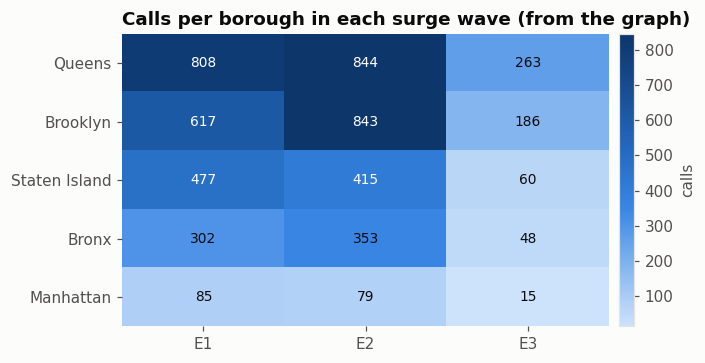

In [ ]:
if RUN_NEO4J:
    t = pd.DataFrame(q("""
        MATCH (e:Episode)<-[:PART_OF]-(:Window)<-[:IN_WINDOW]-(c:Call)-[:IN_BOROUGH]->(b:Borough)
        RETURN e.id AS wave, b.name AS borough, count(c) AS calls"""))
    hm = t.pivot(index="borough", columns="wave", values="calls").fillna(0).astype(int)
    hm = hm.loc[hm.sum(axis=1).sort_values(ascending=False).index]

    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    im = ax.imshow(hm.values, cmap=SEQ, aspect="auto")
    ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels(hm.columns)
    ax.set_yticks(range(hm.shape[0])); ax.set_yticklabels(hm.index)
    for (i, j), v in np.ndenumerate(hm.values):
        ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=9, color="white" if v > hm.values.max() * 0.45 else INK)
    ax.grid(False)
    for s_ in ax.spines.values(): s_.set_visible(False)
    ax.set_title("Calls per borough in each surge wave (from the graph)")
    fig.colorbar(im, ax=ax, label="calls", fraction=0.04, pad=0.02)
    plt.tight_layout(); plt.show()

## 6 · Explain one call

`facts(call_id)` collects everything the graph knows around a call, `describe()` turns it into a sentence, and `draw_explanation()` draws the neighbourhood.

Call: Sewer backup reported. Situation: extreme surge, 403 similar calls city-wide during the previous hour. 

Sewer backup (flood), extreme surge with 403 similar calls city-wide in the previous hour. It belongs to surge wave E1 (01 Sep 20:00 -> 02 Sep 03:00, peak 659 flood calls/h at 01 Sep 22:00, 2,121 flood calls in total). Location: Brooklyn, zone z4066_-7399 (5 other calls in the same 1 km zone that hour). Same borough, same hour: 215 flood. Context: traffic signal failure calls run 5.4x higher while flood is in a surge wave.


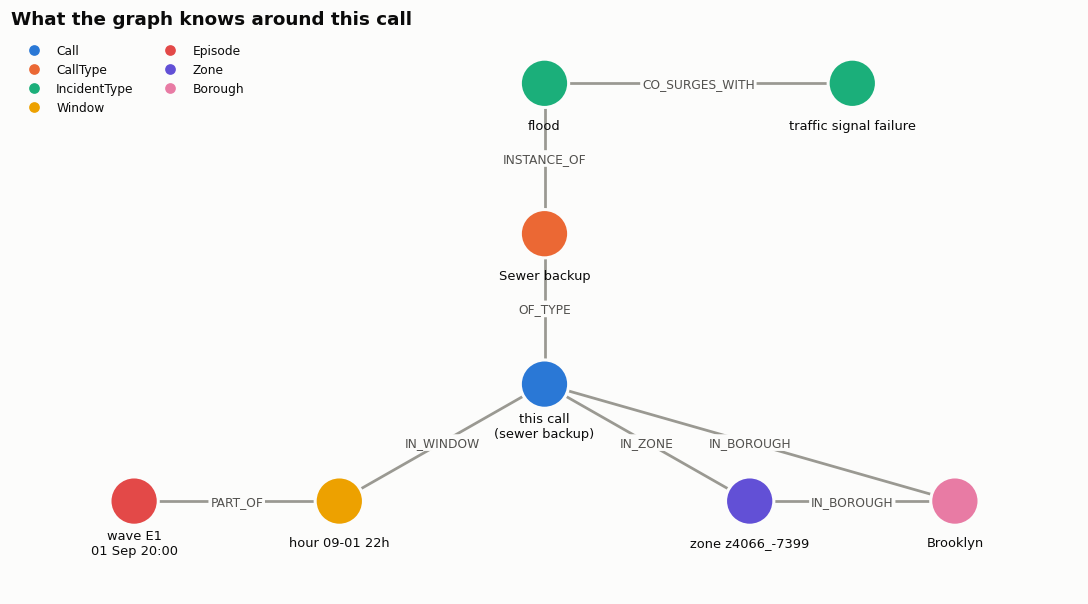

In [ ]:
Q_FACTS = """
MATCH (c:Call {id: $id})-[:OF_TYPE]->(t:CallType)-[:INSTANCE_OF]->(i:IncidentType)
OPTIONAL MATCH (c)-[:IN_WINDOW]->(w:Window)
OPTIONAL MATCH (w)-[:PART_OF]->(e:Episode)
OPTIONAL MATCH (c)-[:IN_BOROUGH]->(b:Borough)
OPTIONAL MATCH (c)-[:IN_ZONE]->(z:Zone)
OPTIONAL MATCH (i)-[cs:CO_SURGES_WITH]-(:IncidentType)
RETURN c.surge_level AS surge_level, c.city_recent_60m AS recent, t.label AS call_label, i.name AS incident_type,
       w.id AS window, w.n_flood AS w_flood, w.n_signal AS w_signal, w.phase AS phase,
       e.id AS wave, e.start AS ep_start, e.end AS ep_end, e.peak_calls AS ep_peak, e.peak_window AS ep_peak_window, e.total_calls AS ep_total,
       b.name AS borough, z.id AS zone,
       startNode(cs).name AS cs_from, endNode(cs).name AS cs_to, cs.ratio AS cs_ratio
LIMIT 1
"""
Q_SAME_ZONE = """
MATCH (c:Call {id: $id})-[:IN_ZONE]->(z:Zone)<-[:IN_ZONE]-(o:Call)
MATCH (c)-[:IN_WINDOW]->(w:Window)<-[:IN_WINDOW]-(o)
WHERE o <> c
RETURN count(o) AS n
"""
Q_SAME_HOUR = """
MATCH (c:Call {id: $id})-[:IN_WINDOW]->(w:Window)
MATCH (c)-[:IN_BOROUGH]->(b:Borough)
MATCH (o:Call)-[:IN_WINDOW]->(w)
MATCH (o)-[:IN_BOROUGH]->(b)
MATCH (o)-[:OF_TYPE]->(:CallType)-[:INSTANCE_OF]->(i:IncidentType)
RETURN i.name AS incident_type, count(o) AS calls ORDER BY calls DESC
"""

def facts(call_id):
    rec = q(Q_FACTS, id=str(call_id))
    if not rec:
        return None
    f = rec[0]
    f["id"] = str(call_id)
    f["same_zone_same_hour"] = (q(Q_SAME_ZONE, id=str(call_id)) or [{"n": 0}])[0]["n"] if f.get("zone") else None
    f["same_hour_borough"]   = {r["incident_type"]: r["calls"] for r in q(Q_SAME_HOUR, id=str(call_id))} if f.get("borough") else {}
    return f

def describe(f):
    if f is None:
        return "(this id is not in the graph - load the same clean export that was used for Qdrant)"
    s = f"{f['call_label']} ({f['incident_type'].replace('_', ' ')}), {f['surge_level']} with {f['recent']} similar calls city-wide in the previous hour"
    if f.get("wave"):
        s += (f". It belongs to surge wave {f['wave']} ({f['ep_start']} -> {f['ep_end']}, peak {f['ep_peak']} flood calls/h at {f['ep_peak_window']}, "
              f"{f['ep_total']:,} flood calls in total)")
    else:
        s += ". It is outside any surge wave"
    if f.get("borough"):
        s += f". Location: {f['borough']}"
        if f.get("zone"):
            s += f", zone {f['zone']} ({f['same_zone_same_hour']} other calls in the same 1 km zone that hour)"
        if f["same_hour_borough"]:
            s += ". Same borough, same hour: " + ", ".join(f"{n} {k.replace('_', ' ')}" for k, n in f["same_hour_borough"].items())
    else:
        s += ". Location unknown (no coordinates in the source)"
    if f.get("cs_ratio"):
        s += f". Context: {f['cs_to'].replace('_', ' ')} calls run {f['cs_ratio']}x higher while {f['cs_from'].replace('_', ' ')} is in a surge wave"
    return s + "."

Q_PATHS = """
MATCH (c:Call {id: $id})
OPTIONAL MATCH p1 = (c)-[:OF_TYPE]->(:CallType)-[:INSTANCE_OF]->(:IncidentType)
OPTIONAL MATCH p2 = (c)-[:IN_WINDOW]->(:Window)-[:PART_OF]->(:Episode)
OPTIONAL MATCH p3 = (c)-[:IN_ZONE]->(:Zone)-[:IN_BOROUGH]->(:Borough)
OPTIONAL MATCH p4 = (c)-[:OF_TYPE]->(:CallType)-[:INSTANCE_OF]->(:IncidentType)-[:CO_SURGES_WITH]-(:IncidentType)
OPTIONAL MATCH p5 = (c)-[:IN_BOROUGH]->(:Borough)
RETURN [p IN [p1, p2, p3, p4, p5] WHERE p IS NOT NULL | p] AS paths
"""
NODE_COLORS = {"Call": "#2a78d6", "CallType": "#eb6834", "IncidentType": "#1baf7a", "Window": "#eda100",
               "Episode": "#e34948", "Zone": "#6250d6", "Borough": "#e87ba4"}

def _node_key(n):
    return getattr(n, "element_id", None) or n.id

def _node_text(n):
    lab, p = next(iter(n.labels)), dict(n.items())
    return {"Call": "this call\n(" + str(p.get("call_type", "")).replace("_", " ") + ")", "CallType": p.get("label"),
            "IncidentType": str(p.get("name", "")).replace("_", " "),
            "Window": "hour " + str(p.get("id", ""))[5:].replace("T", " ") + "h", "Episode": f"wave {p.get('id')}\n{p.get('start', '')}",
            "Zone": f"zone {p.get('id')}", "Borough": p.get("name")}.get(lab, lab)

# fixed layout so the picture always reads the same way: type chain on top, time on the left, place on the right
LAYOUT_SLOTS = {"Call": [(0, 0)], "CallType": [(0, 1.8)], "IncidentType": [(0, 3.6), (3.0, 3.6), (-3.0, 3.6)],
                "Window": [(-2.0, -1.4)], "Episode": [(-4.0, -1.4)], "Zone": [(2.0, -1.4)], "Borough": [(4.0, -1.4)]}

def draw_explanation(call_id):
    recs = q_raw(Q_PATHS, id=str(call_id))
    if not recs:
        print("call not found"); return
    G, labels, kinds = nx.Graph(), {}, {}
    for path in recs[0]["paths"]:
        for n in path.nodes:
            k = _node_key(n); labels[k] = _node_text(n); kinds[k] = next(iter(n.labels)); G.add_node(k)
        for r in path.relationships:
            G.add_edge(_node_key(r.start_node), _node_key(r.end_node), label=r.type)
    used, pos = Counter(), {}
    for k in G.nodes:
        pos[k] = LAYOUT_SLOTS[kinds[k]][used[kinds[k]]]; used[kinds[k]] += 1
    fig, ax = plt.subplots(figsize=(10, 5.6))
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#9a9992", width=1.8)
    nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "label"), ax=ax, font_size=8, font_color=INK2, rotate=False,
                                 bbox=dict(boxstyle="round,pad=0.15", fc=SURF, ec="none"))
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[NODE_COLORS[kinds[k]] for k in G], node_size=1000, edgecolors=SURF, linewidths=2)
    nx.draw_networkx_labels(G, {k: (x, y - 0.5) for k, (x, y) in pos.items()}, labels, ax=ax, font_size=8.5, font_color=INK)
    handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=k) for k, c in NODE_COLORS.items() if k in kinds.values()]
    ax.legend(handles=handles, loc="upper left", fontsize=8, ncol=2)
    ax.set_xlim(-5.2, 5.2); ax.set_ylim(-2.5, 4.2)
    ax.set_title("What the graph knows around this call"); ax.axis("off")
    plt.tight_layout(); plt.show()

if RUN_NEO4J:
    pick = df[(df.call_type == "sewer_backup") & (df.phase == "storm_night") & df.has_geo].iloc[len(df) // 20]
    print("Call:", pick.text, "\n")
    print(describe(facts(pick.point_id)))
    draw_explanation(pick.point_id)
else:
    print("RUN_NEO4J is False.")

## 7 · Combine: Qdrant finds similar calls, Neo4j explains them

For a new situation:

1. build the same generic sentence as in part 1 and embed it,
2. **Qdrant** returns the most similar past calls (and their `point_id`),
3. **Neo4j** is asked about each of those ids,
4. we print a per-call explanation and a short summary of what the matches have in common.

Set `RUN_COMBINE = True` at the top of the notebook. It needs both your Qdrant secrets (`QDRANT_URL`, `QDRANT_API_KEY`) from part 1 and the Neo4j ones above, and the collection from part 1 to exist.

In [ ]:
def surge_level(n):
    return ("isolated report" if n <= 4 else "small cluster" if n <= 29 else
            "busy period" if n <= 99 else "heavy surge" if n <= 299 else "extreme surge")

def make_text(call_label, similar_calls):
    """Same sentence format as part 1."""
    return (f"{call_label} reported. Situation: {surge_level(similar_calls)}, "
            f"{similar_calls} similar calls city-wide during the previous hour.")

_qdrant = {}

def get_qdrant():
    if "client" not in _qdrant:
        try:
            import sentence_transformers, qdrant_client  # noqa: F401
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers", "qdrant-client"], check=True)
        from sentence_transformers import SentenceTransformer
        from qdrant_client import QdrantClient
        url = secret("QDRANT_URL", "Qdrant URL").rstrip("/")
        key = secret("QDRANT_API_KEY", "Qdrant API key", hidden=True)
        _qdrant["client"] = QdrantClient(url=url, api_key=key, timeout=60)
        _qdrant["model"]  = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")   # same model as part 1
    return _qdrant["client"], _qdrant["model"]

def explain_situation(text, k=8, verbose=True):
    client, model = get_qdrant()
    vec  = model.encode(text, normalize_embeddings=True).tolist()
    hits = client.query_points(QDRANT_COLLECTION, query=vec, limit=k, with_payload=True).points
    out  = []
    if verbose:
        print(f"\nNEW SITUATION: {text}\n")
    for rank, h in enumerate(hits, 1):
        f = facts(h.id)
        out.append((h, f))
        if verbose:
            print(f"{rank}. similarity {h.score:.3f} | Qdrant says: {h.payload['text']}")
            print(f"   Neo4j says: {describe(f)}\n")
    known = [f for _, f in out if f]
    if verbose and known:
        waves, boroughs = Counter(f["wave"] or "no wave" for f in known), Counter(f["borough"] or "unknown" for f in known)
        print("What the matches have in common (from the graph):")
        print("  surge waves:", ", ".join(f"{w} x{n}" for w, n in waves.most_common()))
        print("  boroughs   :", ", ".join(f"{b} x{n}" for b, n in boroughs.most_common()))
    return out

if RUN_COMBINE:
    explain_situation(make_text("Sewer backup", 350))       # a wave-peak situation
    explain_situation(make_text("Traffic signal failure", 12))  # a quiet-hour situation
else:
    print("RUN_COMBINE is False - skipping.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


NEW SITUATION: Sewer backup reported. Situation: extreme surge, 350 similar calls city-wide during the previous hour.

1. similarity 1.000 | Qdrant says: Sewer backup reported. Situation: extreme surge, 350 similar calls city-wide during the previous hour.
   Neo4j says: Sewer backup (flood), extreme surge with 350 similar calls city-wide in the previous hour. It belongs to surge wave E1 (01 Sep 20:00 -> 02 Sep 03:00, peak 659 flood calls/h at 01 Sep 22:00, 2,121 flood calls in total). Location: Brooklyn, zone z4066_-7390 (0 other calls in the same 1 km zone that hour). Same borough, same hour: 215 flood. Context: traffic signal failure calls run 5.4x higher while flood is in a surge wave.

2. similarity 1.000 | Qdrant says: Sewer backup reported. Situation: extreme surge, 350 similar calls city-wide during the previous hour.
   Neo4j says: Sewer backup (flood), extreme surge with 350 similar calls city-wide in the previous hour. It belongs to surge wave E1 (01 Sep 20:00 -> 02 Sep 03:

## What's next

* **LLM on top**: pass the Qdrant hits + the graph facts to Claude to turn them into a short operator briefing ("this looks like the start of wave 2, expect signal failures in Queens"). The facts are already structured for that.
* **More streams**: load FloodNet sensors, DOT speeds and outages into the same graph (`Sensor`, `Road` nodes linked to `Zone` and `Window`) and into the same Qdrant collection with a `source` field. The `Window`/`Zone` nodes are the shared join points.
* **Write similarity back**: store the top Qdrant neighbours as `(:Call)-[:SIMILAR_TO {score}]->(:Call)` edges if you want to browse them in Neo4j Bloom.